# Figshare Analysis

Based on data found [here](https://figshare.com/articles/dataset/Dataset_Proper_micro-environment_alleviates_mortality_in_laboratory_mouse_breeding_induced_by_litter_overlap_and_older_dams_/25040630)

In [10]:
# Installation of models if needed
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install plotly

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [11]:
# Imports libraries and data
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
DATA_DIR = ROOT / 'data' / 'figshare'

plt.style.use('seaborn-v0_8')
sns.set_theme(style='whitegrid')
print(f'Working directory: {ROOT}')

# Load the base probability distribution and planning tables
mort = pd.read_csv(DATA_DIR / 'figshare_mortality.csv')

print('Distribution rows:', len(mort))
mort.head()


Working directory: /home/user1/unsw/scif3000-analysis
Distribution rows: 509


,Cage,Litter Number,Litter Code,Strain,"Dam Age on D0, d",Number of Pups Born,Total Number of Pups Found Dead or Missing within day 4 post-partum,"Mortality four days post-partum, %","Pre-weaning mortality (at day 21 post-partum), %",Total Number of Pups Weaned,...,% of Day 0 with Acceleration on Cage Length Direction of - 5G to 0G,% of Day 0 with Acceleration on Cage Length Direction of 0G to 5G,% of Day 0 with Acceleration on Cage Length Direction of 5G to 10G,% of Day 0 with Acceleration on Cage Length Direction of 10G to 15G,"Mean Acceleration on the Cage Length Direction on D0, G","Minimum Acceleration on the Cage Length Direction on D0, G","Maximum Acceleration on the Cage Length Direction on D0, G",Number of Motion Events,"Average Duration of Motion Events, s","Total Duration of Motion Events, s"
0,63,11.0,63.11,C57BL/6,212,12,12,100.00,100.00,0,...,0.0,0.0,99.96,0.04,-0.130,-0.175,-0.100,20.0,82.05,1641.0
1,64,9.0,64.09,C57BL/6,217,3,1,33.33,33.33,2,...,0.0,0.0,100.00,0.00,-0.164,-0.250,-0.125,0.0,0.00,0.0
2,64,8.0,64.08,C57BL/6,241,11,0,0.00,18.18,9,...,0.0,0.0,100.00,0.00,-0.188,-0.250,-0.125,0.0,0.00,0.0
3,26,10.0,26.10,C57BL/6,219,3,3,100.00,100.00,0,...,0.0,0.0,100.00,0.00,-0.209,-0.275,-0.175,6.0,181.50,1089.0
4,55,2.0,55.02,C57BL/6,74,8,0,0.00,0.00,8,...,0.0,0.0,100.00,0.00,-0.212,-0.250,-0.175,5.0,79.80,399.0


# Generate Plots


We can use the above data set to generate the following relations of:

- 

In [ ]:
mort = mort.copy()
mort.columns = [str(col).strip() for col in mort.columns]

numeric_cols = [
    'Dam Age on D0, d',
    'Number of Pups Born',
    'Total Number of Pups Found Dead or Missing within day 4 post-partum',
    'Mortality four days post-partum, %',
    'Pre-weaning mortality (at day 21 post-partum), %',
    'Total Number of Pups Weaned',
    'Age Older Pups, d',
    'Number Older Pups',
    'Room Mean Temperature on Day 0, C',
    'Nest Score on Day 0, based on Hess 2008',
    'Mean Cage T on D0, C',
    'Mean Cage Light Intensity on D0, LX',
    'Mean Acceleration on the Cage Height Direction on D0, G',
    'Mean Acceleration on the Cage Width Direction on D0, G',
    'Mean Acceleration on the Cage Length Direction on D0, G',
    'Number of Motion Events',
    'Average Duration of Motion Events, s',
    'Total Duration of Motion Events, s',
]

for col in numeric_cols:
    if col in mort.columns:
        mort[col] = pd.to_numeric(mort[col], errors='coerce')

print('Dataset shape:', mort.shape)
print('Unique strains:', mort['Strain'].dropna().unique())
print('Older pups present counts:\n', mort['Older Pups Were Present on Day 0?'].value_counts(dropna=False))
print('Season counts:\n', mort['Day 0 Season'].value_counts(dropna=False))


Dataset shape: (509, 75)
Unique strains: <StringArray>
['C57BL/6']
Length: 1, dtype: str
Older pups present counts:
 Older Pups Were Present on Day 0?
NO     289
YES    220
Name: count, dtype: int64
Season counts:
 Day 0 Season
WIN    152
FAL    121
SUM    120
SPR    116
Name: count, dtype: int64


In [13]:
# Outcome summary statistics
outcomes = ['Mortality four days post-partum, %', 'Pre-weaning mortality (at day 21 post-partum), %']
for col in outcomes:
    s = mort[col].dropna()
    print(f'\n{col}')
    print(f'  mean={s.mean():.2f}, median={s.median():.2f}, min={s.min():.2f}, max={s.max():.2f}, n={len(s)}')



Mortality four days post-partum, %
  mean=27.91, median=10.00, min=0.00, max=100.00, n=509

Pre-weaning mortality (at day 21 post-partum), %
  mean=31.89, median=14.29, min=0.00, max=100.00, n=509


In [14]:
# Most correlated variables with the two mortality outcomes
numeric = mort.select_dtypes(include='number')
corr = numeric.corr(numeric_only=True)

for outcome in outcomes:
    print(f'\nTop correlations with {outcome}:')
    top = corr[outcome].drop(outcome).sort_values(ascending=False).head(8)
    print(top.round(3).to_string())



Top correlations with Mortality four days post-partum, %:
Pre-weaning mortality (at day 21 post-partum), %                       0.933
Total Number of Pups Found Dead or Missing within day 4 post-partum    0.742
Age Older Pups, d                                                      0.361
Dam Age on D0, d                                                       0.275
Litter Number                                                          0.245
Number Older Pups                                                      0.189
Minimum Acceleration on the Cage Width Direction on D0, G              0.139
Average Duration of Motion Events, s                                   0.126

Top correlations with Pre-weaning mortality (at day 21 post-partum), %:
Mortality four days post-partum, %                                     0.933
Total Number of Pups Found Dead or Missing within day 4 post-partum    0.688
Age Older Pups, d                                                      0.350
Dam Age on D0, d     

In [15]:
# Mortality by older-pup overlap and season
print('Mortality by older-pup overlap:')
print(mort.groupby('Older Pups Were Present on Day 0?')['Mortality four days post-partum, %'].agg(['mean', 'median', 'count']).round(2))

print('\nMortality by season:')
print(mort.groupby('Day 0 Season')['Mortality four days post-partum, %'].agg(['mean', 'median', 'count']).round(2))


Mortality by older-pup overlap:
                                    mean  median  count
Older Pups Were Present on Day 0?                      
NO                                 19.22    0.00    289
YES                                39.33   23.61    220

Mortality by season:
               mean  median  count
Day 0 Season                      
FAL           23.26    0.00    121
SPR           28.77   11.11    116
SUM           36.39   14.29    120
WIN           24.27    0.00    152


In [16]:
# Dam age effect
age_bins = pd.cut(mort['Dam Age on D0, d'], bins=[0, 120, 180, 240, 300, 360, 420, 500], right=False, include_lowest=True)
age_summary = mort.groupby(age_bins)['Mortality four days post-partum, %'].mean().round(2)
print(age_summary)


Dam Age on D0, d
[0, 120)       19.64
[120, 180)     23.48
[180, 240)     30.12
[240, 300)     41.97
[300, 360)     41.57
[360, 420)     55.42
[420, 500)    100.00
Name: Mortality four days post-partum, %, dtype: float64


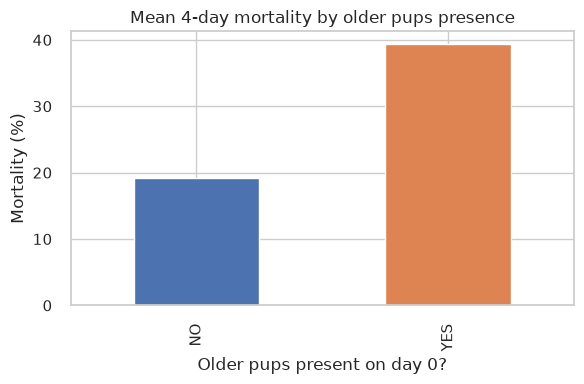

In [17]:
# Plot 1: mortality by older pups presence
older_plot = mort.groupby('Older Pups Were Present on Day 0?')['Mortality four days post-partum, %'].mean()
plt.figure(figsize=(6, 4))
older_plot.plot(kind='bar', color=['#4C72B0', '#DD8452'])
plt.title('Mean 4-day mortality by older pups presence')
plt.ylabel('Mortality (%)')
plt.xlabel('Older pups present on day 0?')
plt.tight_layout()
plt.show()


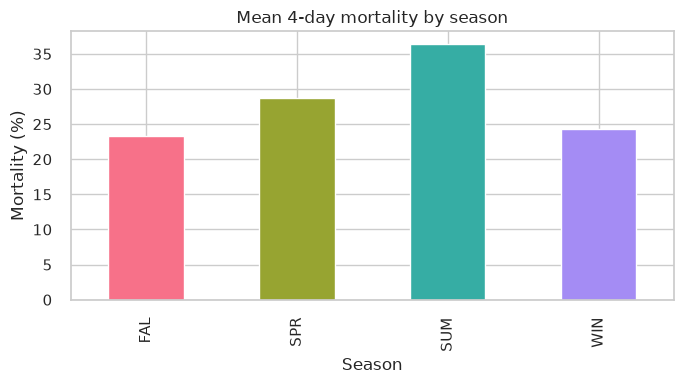

In [18]:
# Plot 2: mortality by season
season_plot = mort.groupby('Day 0 Season')['Mortality four days post-partum, %'].mean()
plt.figure(figsize=(7, 4))
season_plot.plot(kind='bar', color=sns.color_palette('husl', n_colors=len(season_plot)))
plt.title('Mean 4-day mortality by season')
plt.ylabel('Mortality (%)')
plt.xlabel('Season')
plt.tight_layout()
plt.show()


## Interpretation

The strongest observations in this dataset are:

- older dams show markedly higher mortality
- the presence of older pups on day 0 strongly increases mortality
- summer shows the highest mean mortality
- total pups weaned and pups dead/missing are the strongest correlated variables with mortality

These relationships suggest a biologically meaningful risk pattern rather than random noise.

Further todo:
- a logistic regression model
- a feature importance table
